# Phase 2 — Evidence-Locked LLM Explanation Layer (implementation + model selection)

Takes the structured evidence PGExplainer produces for a flagged transaction
(`explain_transaction(transaction_id)`, see `pgexplainer.ipynb`) and turns it into the plain-language
explanation an analyst reads. It also runs the **model selection**: several open-source LLMs are run on the
*same* evidence with the *same* prompt, scored, and one is chosen to be the project's LLM layer.

## Decisions

**Agreed** (earlier project decisions + this session)

1. The LLM layer consumes `explain_transaction()` output only, and runs only for transactions the classifier
   flagged — PGExplainer is trained on predicted positives only, so nothing else has evidence to explain.
2. Evidence-locking: the explanation may cite only what is inside the evidence object. Pattern-type labels
   (fan-in, cycle, ...) never enter the prompt; they stay diagnostic-only.
3. **Open-source models only, from Hugging Face or Ollama.** No proprietary API in the live pipeline, and none
   used as a judge either.

**Proposed defaults** (chosen in this notebook — every one is isolated in a config or a single function, so
changing your mind is cheap)

4. Four candidates from four labs, all comfortable on the 15.7 GB A16: `Qwen3-8B` (Alibaba),
   `Llama-3.1-8B-Instruct` (Meta), `Gemma-3-12B-it` (Google), `Phi-4-mini-instruct` (Microsoft, 3.8B).
   Three newer-generation models from the Ollama library are pre-listed but **disabled** (not verified here).
5. One prompt for every candidate — no per-model prompt tuning. The comparison is about which model follows
   the same instruction most faithfully, not which prompt flatters which model.
6. Greedy decoding (temperature 0): the same evidence must give the same explanation — auditable and cacheable.
7. **Hard gate first.** A model that fails a generation, cites a transaction ID or account that is not in its
   evidence, or exceeds the VRAM budget cannot win, however fluent it reads.
8. Survivors are compared in stages — grounded figures → unsupported AML-typology claims → coverage of the
   explainer's top evidence → (optional blind human rating) → format rubric → speed/VRAM. A difference smaller
   than `TIE_MARGIN` is treated as noise at this sample size and the next stage decides.
9. A serving wrapper with a deterministic fallback: if a live response ever fails the same identifier check,
   the analyst gets an evidence-only template instead of the LLM text (Section 10). *Proposal — confirm with
   whoever owns the backend.*

## What has and hasn't been verified

Everything except real model inference was executed end-to-end in a dry run with an offline stub (no GPU, no
Ollama, no Hugging Face access), and every metric has self-tests with known-good and known-bad responses
(Section 5). **Real inference — the Ollama / Hugging Face calls — has not been run yet;** it happens for the
first time when this executes on the server. No results are pre-filled: the winner is whatever the evaluation on
real evidence says.

## 1. Setup

Two ways to serve each candidate — pick one with `SERVING_BACKEND`. **Ollama is the recommended default**: one
daemon, `pull` and go, automatic GGUF quantization. Hugging Face `transformers` (4-bit via `bitsandbytes`) is
included too; it gives finer control over generation and is the path you'd need if a model is ever fine-tuned.

In [1]:
import os, sys, json, time, re, random, gc, hashlib, subprocess, statistics as st
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd

NOTEBOOK_VERSION = "1.0"

# --- Paths -------------------------------------------------------------------
# Same artifact folder as the rest of the pipeline. Override with AML_DATA_DIR when running elsewhere
# (a teammate's laptop, Colab, ...). If it isn't found the notebook still runs standalone on mock evidence.
DATA_DIR = Path(os.environ.get("AML_DATA_DIR", "/home/jovyan/AML_Project/Data/Bassam Data"))
PIPELINE_ARTIFACTS_AVAILABLE = DATA_DIR.exists()
OUT_DIR = (DATA_DIR / "llm_layer") if PIPELINE_ARTIFACTS_AVAILABLE else Path("./llm_layer_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)
if not PIPELINE_ARTIFACTS_AVAILABLE:
    print(f"NOTE: {DATA_DIR} not found -> standalone mode. Outputs go to {OUT_DIR.resolve()}; "
          "Section 2 will use the synthetic mock evidence.")

# --- Serving -----------------------------------------------------------------
SERVING_BACKEND = "ollama"      # "ollama" | "hf_transformers"
OLLAMA_HOST = "http://localhost:11434"

# --- Decoding: greedy on purpose (same evidence -> same explanation) ------------
MAX_NEW_TOKENS = 400
OLLAMA_NUM_CTX = 8192           # Ollama's default context can silently truncate a long evidence prompt

# --- Evaluation / selection --------------------------------------------------
RANDOM_SEED = 3000              # continues the project's seed pattern (42 / 1000-1004 / 2000 / 3000)
N_EVAL_TRANSACTIONS = 30
TIE_MARGIN = 0.05               # metrics within this of the best are "tied" at a selection stage
MAX_LLM_VRAM_GB = 12.0          # placeholder budget for the LLM next to PNA + PGExplainer on the 15.7 GB GPU
random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)

# --- Candidate registry ------------------------------------------------------
# thinking=True marks hybrid-reasoning models whose <think> mode must be switched off so answers stay short
# and parseable. hf_repo=None means "Ollama only unless you fill it in".
CANDIDATE_MODELS = [
    dict(name="qwen3-8b",    ollama_tag="qwen3:8b",    hf_repo="Qwen/Qwen3-8B",
         license="Apache-2.0", params_b=8.0, thinking=True, enabled=True),
    dict(name="llama3.1-8b", ollama_tag="llama3.1:8b", hf_repo="meta-llama/Llama-3.1-8B-Instruct",
         license="Llama 3.1 Community License (gated on HF: accept it on huggingface.co first)",
         params_b=8.0, thinking=False, enabled=True),
    dict(name="gemma3-12b",  ollama_tag="gemma3:12b",  hf_repo="google/gemma-3-12b-it",
         license="Gemma Terms of Use", params_b=12.0, thinking=False, enabled=True),
    dict(name="phi4-mini",   ollama_tag="phi4-mini",   hf_repo="microsoft/Phi-4-mini-instruct",
         license="MIT", params_b=3.8, thinking=False, enabled=True),
    # Newer-generation tags reported in Ollama model roundups (Aug 2026). Disabled by default: their chat templates /
    # thinking behaviour weren't verified here. Set enabled=True to include one; check the thinking flag first.
    dict(name="qwen3.5-9b",    ollama_tag="qwen3.5:9b",    hf_repo=None, license="check model card",
         params_b=9.0, thinking=False, enabled=False),
    dict(name="gemma4-12b",    ollama_tag="gemma4:12b",    hf_repo=None, license="check model card",
         params_b=12.0, thinking=False, enabled=False),
    dict(name="granite4.2-8b", ollama_tag="granite4.2:8b", hf_repo=None, license="check model card",
         params_b=8.0, thinking=False, enabled=False),
]
ACTIVE_MODELS = [m for m in CANDIDATE_MODELS if m["enabled"]]

print(f"Serving backend : {SERVING_BACKEND}")
print(f"Active models   : {[m['name'] for m in ACTIVE_MODELS]}")

NOTE: /home/jovyan/AML_Project/Data/Bassam Data not found -> standalone mode. Outputs go to /home/jovyan/AML_Project/NoteBooks/Bassam/llm_layer_outputs; Section 2 will use the synthetic mock evidence.
Serving backend : ollama
Active models   : ['qwen3-8b', 'llama3.1-8b', 'gemma3-12b', 'phi4-mini']


## 2. Load evidence from PGExplainer

`explain_transaction(transaction_id)` is the only evidence source this layer may use. Nothing here reads
`graph_data.pt` or the raw transaction table directly — that would defeat evidence-locking, because the LLM
must explain what PGExplainer actually attributed, not what this notebook could look up on its own.

**Two things to check the first time this runs on the server:**

1. **Key names.** `adapt_evidence()` is the single place that maps `explain_transaction()`'s real output to the
   shape everything downstream uses (see `MOCK_EVIDENCE_EXAMPLES` for that shape). If the real keys differ,
   this is a one-function fix.
2. **Values must be human-readable.** `raw_value` and the amounts inside `raw_fields` must already be *decoded*
   out of log/scaled space (`decode_transaction_features()`). If they aren't, the LLM will faithfully explain
   meaningless numbers such as "scaled_log_amount_paid = 1.83" — decode them inside `adapt_evidence()` before
   they reach the prompt.

How `explain_transaction` is found: already defined in this kernel → else `from pgexplainer_utils import
explain_transaction` (the importable module the backend will need anyway; see Next steps) → else the notebook
falls back to the synthetic mock evidence so everything downstream can still be read and tested.

In [2]:
# Three clearly SYNTHETIC evidence objects, covering the cases the prompt has to handle:
#   1) a normal flagged transaction with a full neighbourhood,
#   2) an EMPTY neighbourhood (an isolated account -- the ~22% of nodes outside the giant component),
#   3) a borderline case where the probability sits just under the decision threshold (confidence_warning).
# Values are fabricated for testing; they only mimic the real formats.
MOCK_EVIDENCE_EXAMPLES = [
    {
        "transaction_id": "TXN00081234", "predicted_label": "laundering",
        "predicted_probability": 0.9991, "decision_threshold": 0.9967,
        "target": {
            "raw_fields": {"Timestamp": "2022-09-14 03:41:00", "From Bank_Account": "3402_8129331",
                           "To Bank_Account": "3402_8129331", "Amount Paid": 48219.30, "Amount Received": 48219.30,
                           "Payment Format": "ACH", "Payment Currency": "US Dollar", "Receiving Currency": "US Dollar"},
            "feature_attribution": [
                {"feature": "log_amount_paid", "raw_value": 48219.30, "importance": 0.41},
                {"feature": "is_self_loop", "raw_value": 1, "importance": 0.33},
                {"feature": "is_night", "raw_value": 1, "importance": 0.19},
                {"feature": "hours_since_last_tx", "raw_value": 0.02, "importance": 0.07}],
            "categorical_fields": {"Payment Format": "ACH"},
        },
        "neighborhood": [
            {"rank": 1, "transaction_id": "TXN00081201", "importance_score": 0.88,
             "raw_fields": {"Amount Paid": 47800.10, "Payment Format": "ACH"}},
            {"rank": 2, "transaction_id": "TXN00081190", "importance_score": 0.74,
             "raw_fields": {"Amount Paid": 46990.00, "Payment Format": "ACH"}},
            {"rank": 3, "transaction_id": "TXN00080955", "importance_score": 0.61,
             "raw_fields": {"Amount Paid": 12000.00, "Payment Format": "Wire"}}],
    },
    {
        "transaction_id": "TXN02417766", "predicted_label": "laundering",
        "predicted_probability": 0.9983, "decision_threshold": 0.9967,
        "target": {
            "raw_fields": {"Timestamp": "2022-09-05 14:12:00", "From Bank_Account": "70_100428660",
                           "To Bank_Account": "1120_80021DAD0", "Amount Paid": 9450.00, "Amount Received": 9450.00,
                           "Payment Format": "Wire", "Payment Currency": "Euro", "Receiving Currency": "Euro"},
            "feature_attribution": [
                {"feature": "is_cross_bank", "raw_value": 1, "importance": 0.46},
                {"feature": "log_amount_paid", "raw_value": 9450.00, "importance": 0.31},
                {"feature": "tx_count_cumulative", "raw_value": 1, "importance": 0.14}],
            "categorical_fields": {"Payment Format": "Wire"},
        },
        "neighborhood": [],
    },
    {
        "transaction_id": "TXN00566001", "predicted_label": "laundering",
        "predicted_probability": 0.9958, "decision_threshold": 0.9967, "confidence_warning": True,
        "target": {
            "raw_fields": {"Timestamp": "2022-09-09 22:30:00", "From Bank_Account": "1120_80021DAD0",
                           "To Bank_Account": "3402_8129331", "Amount Paid": 3120.55, "Amount Received": 3120.55,
                           "Payment Format": "ACH", "Payment Currency": "US Dollar", "Receiving Currency": "US Dollar"},
            "feature_attribution": [
                {"feature": "rapid_tx_1h", "raw_value": 1, "importance": 0.38},
                {"feature": "is_cross_bank", "raw_value": 1, "importance": 0.27},
                {"feature": "is_night", "raw_value": 1, "importance": 0.22}],
            "categorical_fields": {"Payment Format": "ACH"},
        },
        "neighborhood": [
            {"rank": 1, "transaction_id": "TXN00565990", "importance_score": 0.79,
             "raw_fields": {"Amount Paid": 3100.00, "Payment Format": "ACH",
                            "From Bank_Account": "1120_80021DAD0", "To Bank_Account": "3402_8129331"}},
            {"rank": 2, "transaction_id": "TXN00565957", "importance_score": 0.52,
             "raw_fields": {"Amount Paid": 3150.20, "Payment Format": "ACH"}}],
    },
]

REQUIRED_TOP_KEYS = {"transaction_id", "predicted_label", "predicted_probability", "decision_threshold", "target"}


LABEL_NAMES = {1: "laundering", 0: "normal"}          # in case explain_transaction() returns the class index


def _to_native(x):
    """numpy / torch scalars and arrays -> plain Python, so the evidence is JSON-serialisable for the prompt."""
    if isinstance(x, dict):
        return {str(k): _to_native(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_to_native(v) for v in x]
    if isinstance(x, (str, int, float, bool)) or x is None:
        return x
    if hasattr(x, "item") and getattr(x, "ndim", 1) == 0:
        return x.item()
    if hasattr(x, "tolist"):
        return x.tolist()
    return str(x)


def adapt_evidence(raw: dict) -> dict:
    """Map explain_transaction()'s real output onto the shape used below. EDIT HERE if the keys differ --
    everything downstream only ever sees the adapted dict. Decode log/scaled values to human-readable here too."""
    missing = REQUIRED_TOP_KEYS - set(raw.keys())
    if missing:
        raise KeyError(f"explain_transaction() output is missing {sorted(missing)} -- update adapt_evidence().")
    ev = _to_native(raw)
    ev["predicted_label"] = LABEL_NAMES.get(ev["predicted_label"], ev["predicted_label"])
    ev.setdefault("neighborhood", [])
    ev["target"] = dict(ev["target"])
    ev["target"].setdefault("raw_fields", {})
    ev["target"].setdefault("feature_attribution", [])
    ev["target"].setdefault("categorical_fields", {})
    ev.setdefault("confidence_warning", bool(ev["predicted_probability"] < ev["decision_threshold"]))
    return ev


def load_predicted_positive_txn_ids(phase="val"):
    """Transaction IDs of the edges the frozen classifier flagged in a phase (pgexplainer.ipynb Section 5)."""
    import torch
    pp = torch.load(DATA_DIR / "predicted_positive_edges.pt", map_location="cpu", weights_only=False)
    idxs = pp[phase]
    if str(getattr(idxs, "dtype", "")) in ("torch.bool", "bool"):      # a boolean mask over all edges, not indices
        idxs = idxs.nonzero().flatten()
    idxs = idxs.tolist() if hasattr(idxs, "tolist") else list(idxs)
    path = DATA_DIR / "transaction_ids.npy"
    try:
        txn_ids = np.load(path, mmap_mode="r")
    except ValueError:                       # object-dtype array can't be memory-mapped
        txn_ids = np.load(path, allow_pickle=True)
    return [str(txn_ids[i]) for i in idxs]


USING_MOCK_EVIDENCE = True
REAL_TXN_POOL = None

explain_fn = globals().get("explain_transaction")
if explain_fn is None:
    try:
        from pgexplainer_utils import explain_transaction as explain_fn
    except ImportError:
        explain_fn = None

if PIPELINE_ARTIFACTS_AVAILABLE and explain_fn is not None:
    try:
        REAL_TXN_POOL = load_predicted_positive_txn_ids("val")
        adapt_evidence(explain_fn(REAL_TXN_POOL[0]))              # probe one real transaction
        USING_MOCK_EVIDENCE = False
        print(f"explain_transaction() works; {len(REAL_TXN_POOL):,} predicted-positive val transactions available.")
    except Exception as e:
        print(f"Real evidence path failed ({type(e).__name__}: {e}) -> mock evidence.")
else:
    why = "pipeline artifacts not found" if not PIPELINE_ARTIFACTS_AVAILABLE else "explain_transaction not in scope"
    print(f"Using synthetic MOCK evidence ({why}). See the markdown above for how to wire in the real thing.")
print("USING_MOCK_EVIDENCE =", USING_MOCK_EVIDENCE)

Using synthetic MOCK evidence (pipeline artifacts not found). See the markdown above for how to wire in the real thing.
USING_MOCK_EVIDENCE = True


### 2a. The evaluation sample

In production this layer only ever runs on predicted-positive transactions (Decision 1). With the real pipeline
available, sample from the **val** split's predicted positives — not train (PGExplainer was trained on it) and
not test (kept untouched for a final confirmation run, same discipline as the GNN stage).

The sample is saved to `eval_sample.json` and reused on re-runs, so every candidate — today or after a kernel
restart — sees byte-identical evidence, and teammates without the heavy pipeline can still run the LLM
evaluation from a copy of that file. Set `REBUILD_SAMPLE = True` to regenerate it.

In [3]:
REBUILD_SAMPLE = False
SAMPLE_PATH = OUT_DIR / "eval_sample.json"


def build_evaluation_sample():
    """Returns (sample, used_mock). Reuses a saved real sample if one exists."""
    if SAMPLE_PATH.exists() and not REBUILD_SAMPLE:
        saved = json.loads(SAMPLE_PATH.read_text())
        if (not saved["mock"]) or USING_MOCK_EVIDENCE:      # a real sample is always reusable
            print(f"Reusing saved sample from {SAMPLE_PATH.name} (mock={saved['mock']}).")
            return saved["sample"], saved["mock"]
    if USING_MOCK_EVIDENCE:
        sample, used_mock = [adapt_evidence(e) for e in MOCK_EVIDENCE_EXAMPLES], True
    else:
        rng = random.Random(RANDOM_SEED)
        ids = rng.sample(REAL_TXN_POOL, k=min(N_EVAL_TRANSACTIONS, len(REAL_TXN_POOL)))
        sample, used_mock = [adapt_evidence(explain_fn(t)) for t in ids], False
    SAMPLE_PATH.write_text(json.dumps({"mock": used_mock, "sample": sample}, indent=1, default=str))
    return sample, used_mock


EVAL_SAMPLE, _sample_is_mock = build_evaluation_sample()
USING_MOCK_EVIDENCE = _sample_is_mock
SAMPLE_BY_ID = {e["transaction_id"]: e for e in EVAL_SAMPLE}
print(f"Evaluation sample: {len(EVAL_SAMPLE)} transaction(s) "
      f"({'MOCK / synthetic' if USING_MOCK_EVIDENCE else 'real, val split'})")

Evaluation sample: 3 transaction(s) (MOCK / synthetic)


## 3. Evidence-locked prompt

One prompt, stated once, applied identically to every candidate (Decision 5). The evidence goes in as JSON
rather than prose: a model stays grounded far more reliably when the exact allowed IDs sit in front of it
verbatim than when it has to dig them out of a paragraph.

The prompt also has to cope with the two awkward cases the mock examples cover: an **empty neighbourhood**
(say so, don't invent one) and a **`confidence_warning`** (say the probability is near or under the threshold).

In [4]:
SYSTEM_PROMPT = """You are a fraud-investigation assistant helping an anti-money-laundering (AML) analyst understand why a graph neural network flagged ONE specific transaction as laundering.

You receive an EVIDENCE object produced by the model's own explainability layer (PGExplainer):
- "predicted_probability" / "decision_threshold": how confident the model was. If "confidence_warning" is true, the probability is close to or below the threshold and you must say so plainly.
- "target.raw_fields": the flagged transaction's own fields.
- "target.feature_attribution": which of the flagged transaction's own features drove the decision (higher importance = more influential).
- "neighborhood": other transactions in its local network that most influenced the decision, ranked (rank 1 = most influential). It can be empty.

Rules, no exceptions:
1. Use ONLY facts that appear in the EVIDENCE. Never invent or infer a transaction ID, account, amount, date, or laundering pattern name that is not in it.
2. When you refer to a transaction or an account, write its ID exactly as it appears in the EVIDENCE.
3. If the neighborhood is empty, or the evidence cannot explain something, say so instead of filling the gap.
4. Describe what the evidence shows; do not accuse anyone or state legal conclusions.

Write 3-6 sentences of plain prose (no lists, no headings, no preamble) that an analyst could act on."""


def build_prompt(evidence: dict):
    """(system, user). Identical for every candidate model."""
    return SYSTEM_PROMPT, "EVIDENCE:\n" + json.dumps(evidence, indent=2, ensure_ascii=False)


_sys, _usr = build_prompt(EVAL_SAMPLE[0])
print(f"System prompt: {len(_sys.split())} words | user prompt for sample[0]: ~{len(_usr) // 4} tokens")

System prompt: 212 words | user prompt for sample[0]: ~415 tokens


## 4. Serving clients

Both backends expose the same call — `generate(model_entry, system, user) -> {text, latency_s, output_tokens}`
— so nothing downstream knows which one produced a response.

### One-time setup on the server

**Ollama** (recommended)
```bash
curl -fsSL https://ollama.com/install.sh | sh                                   # skip if already installed
nohup ollama serve > /home/jovyan/AML_Project/ollama_serve.log 2>&1 &           # check with: ollama ps
ollama pull qwen3:8b && ollama pull llama3.1:8b && ollama pull gemma3:12b && ollama pull phi4-mini
```

**Hugging Face `transformers`** (4-bit NF4 via bitsandbytes — every candidate then fits well under 15.7 GB, one
model at a time)
```bash
pip install --upgrade transformers accelerate bitsandbytes
huggingface-cli login      # needed once for the gated meta-llama repo (accept its license on huggingface.co first)
```

Known quirks handled below: Qwen3's `<think>` mode is switched off; a chat template with no `system` role gets
the system text folded into the user turn; stray `<think>` blocks are stripped from any output; Ollama's default
context is raised to `OLLAMA_NUM_CTX` because a silently truncated prompt would drop the very rule we depend on.

### 4a. Ollama client

In [5]:
import requests

_THINK_CLOSED = re.compile(r"<think>.*?</think>", re.S)
_THINK_OPEN = re.compile(r"<think>.*$", re.S)


def strip_think(text: str) -> str:
    return _THINK_OPEN.sub("", _THINK_CLOSED.sub("", text)).strip()


def _norm_tag(tag):
    return tag if ":" in tag else tag + ":latest"


def ollama_generate(m, system, user, timeout=300):
    payload = {
        "model": m["ollama_tag"],
        "messages": [{"role": "system", "content": system}, {"role": "user", "content": user}],
        "stream": False,
        "keep_alive": "10m",
        "options": {"temperature": 0, "seed": RANDOM_SEED, "num_predict": MAX_NEW_TOKENS, "num_ctx": OLLAMA_NUM_CTX},
    }
    if m.get("thinking"):
        payload["think"] = False
    t0 = time.time()
    r = requests.post(f"{OLLAMA_HOST}/api/chat", json=payload, timeout=timeout)
    if r.status_code != 200:
        raise RuntimeError(f"Ollama {r.status_code} for {m['ollama_tag']}: {r.text[:300]}")
    data = r.json()
    return {"text": strip_think(data["message"]["content"]), "latency_s": time.time() - t0,
            "output_tokens": data.get("eval_count")}

### 4b. Hugging Face client

In [6]:
_hf_cache = {}


def _load_hf_model(repo_id):
    if repo_id in _hf_cache:
        return _hf_cache[repo_id]
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.bfloat16, bnb_4bit_quant_type="nf4")
    tok = AutoTokenizer.from_pretrained(repo_id)
    try:
        model = AutoModelForCausalLM.from_pretrained(repo_id, quantization_config=bnb, device_map="auto")
    except (ValueError, KeyError):
        # Multimodal checkpoints (e.g. Gemma 3) may only register under the image-text-to-text auto class.
        from transformers import AutoModelForImageTextToText
        model = AutoModelForImageTextToText.from_pretrained(repo_id, quantization_config=bnb, device_map="auto")
    _hf_cache[repo_id] = (tok, model)
    return tok, model


def hf_generate(m, system, user):
    import torch
    if not m.get("hf_repo"):
        raise RuntimeError(f"{m['name']} has no hf_repo configured -- use the Ollama backend or fill it in.")
    tok, model = _load_hf_model(m["hf_repo"])
    extra = {"enable_thinking": False} if m.get("thinking") else {}

    def _encode(messages):
        return tok.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt",
                                       return_dict=True, **extra).to(model.device)
    try:
        inputs = _encode([{"role": "system", "content": system}, {"role": "user", "content": user}])
    except Exception:                       # template without a system role -> fold it into the user turn
        inputs = _encode([{"role": "user", "content": system + "\n\n" + user}])

    t0 = time.time()
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                             temperature=None, top_p=None, top_k=None, pad_token_id=tok.eos_token_id)
    latency = time.time() - t0
    gen = out[0][inputs["input_ids"].shape[1]:]
    return {"text": strip_think(tok.decode(gen, skip_special_tokens=True)),
            "latency_s": latency, "output_tokens": int(gen.shape[0])}

### 4c. Unified call, GPU helpers, backend check, offline stub

In [7]:
def generate_explanation(model_entry, evidence):
    """The one call the rest of the notebook (and later the backend) makes."""
    system, user = build_prompt(evidence)
    if SERVING_BACKEND == "ollama":
        return ollama_generate(model_entry, system, user)
    if SERVING_BACKEND == "hf_transformers":
        return hf_generate(model_entry, system, user)
    raise ValueError(f"Unknown SERVING_BACKEND: {SERVING_BACKEND}")


def gpu_mem_used_mb():
    """Whole-GPU memory in use (MB) via nvidia-smi, or None. NOTE the JupyterHub GPU is shared with teammates'
    jobs, so only *differences* taken back-to-back are meaningful (used below for a per-model footprint)."""
    try:
        out = subprocess.check_output(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"],
                                      text=True, timeout=10)
        return int(out.strip().splitlines()[0])
    except Exception:
        return None


def unload_model(m):
    """Free the GPU between candidates so the next footprint reading isn't contaminated."""
    if SERVING_BACKEND == "ollama":
        try:
            requests.post(f"{OLLAMA_HOST}/api/generate", json={"model": m["ollama_tag"], "keep_alive": 0}, timeout=30)
        except Exception:
            pass
    else:
        _hf_cache.pop(m.get("hf_repo"), None)
        gc.collect()
        try:
            import torch
            torch.cuda.empty_cache()
        except Exception:
            pass
    time.sleep(2)


def check_backend_ready(models):
    """Fail early and clearly (not 30 minutes in) if the backend or a model isn't there."""
    if SERVING_BACKEND == "ollama":
        try:
            tags = requests.get(f"{OLLAMA_HOST}/api/tags", timeout=10).json().get("models", [])
        except Exception as e:
            raise RuntimeError(f"Can't reach Ollama at {OLLAMA_HOST} ({e}). Start it: nohup ollama serve &") from e
        have = {_norm_tag(t["name"]) for t in tags}
        missing = [m["ollama_tag"] for m in models if _norm_tag(m["ollama_tag"]) not in have]
        if missing:
            raise RuntimeError("Not pulled yet: " + ", ".join(missing) + "  ->  run `ollama pull <tag>` for each.")
    else:
        for pkg in ("transformers", "bitsandbytes", "accelerate"):
            __import__(pkg)
        skipped = [m["name"] for m in models if not m.get("hf_repo")]
        if skipped:
            raise RuntimeError(f"No hf_repo for {skipped}: disable them or fill in hf_repo.")
    print(f"Backend '{SERVING_BACKEND}' ready for {[m['name'] for m in models]}")


# Offline stub -- used ONLY by dry_run() to prove the notebook's plumbing works without a GPU or model.
# It is deterministic and identical across "models", so it says nothing about any real model.
def _offline_fake_generate(m, ev):
    t0 = time.time()
    feats = sorted(ev["target"].get("feature_attribution", []), key=lambda f: -abs(f.get("importance", 0)))[:2]
    feat_txt = " and ".join(str(f["feature"]).replace("_", " ") for f in feats) or "its own fields"
    nb = ev.get("neighborhood", [])
    nb_txt = (f" The most influential related transaction is {nb[0]['transaction_id']}." if nb
              else " No related transactions were available in the evidence.")
    warn = " The probability is close to or below the decision threshold, so treat this with caution." \
        if ev.get("confidence_warning") else ""
    text = (f"[OFFLINE STUB - {m['name']}] {ev['transaction_id']} was flagged as {ev['predicted_label']} with "
            f"probability {ev['predicted_probability']:.4f} against a threshold of {ev['decision_threshold']:.4f}. "
            f"The model weighted {feat_txt} most heavily.{nb_txt}{warn}")
    return {"text": text, "latency_s": time.time() - t0 + 0.001, "output_tokens": len(text.split())}

## 5. Evaluation metrics

One hard gate and four soft signals. The gate is the evidence-locking principle in executable form; the soft signals
exist because — as the dry run makes obvious — several fluent models will all pass the gate, and something has to
separate them that isn't just "which one is smallest".

| Metric | Role | What it measures | Known limits |
|---|---|---|---|
| **Identifier check** | **hard gate** | every `TXN########` and `Bank_Account` ID in the response must occur in the evidence it was given | doesn't catch an unsupported *claim* that uses no ID |
| Figure grounding | stage 1 | amounts, probabilities, dates and times in the response that appear in the evidence (±0.05%) | a derived number (a sum) counts as ungrounded; dates written in words aren't parsed |
| Typology claims | stage 2 | AML jargon (`fan-out`, `structuring`, `mule`, ...) in the response that the evidence doesn't contain — i.e. post-hoc rationalisation | short lexicon; edit `TYPOLOGY_TERMS` |
| Evidence coverage | stage 3 | share of the explainer's top-3 neighbours and top-3 features that the response actually uses | lexical cues (`FEATURE_CUES`, editable), so paraphrases can be missed |
| Rubric | stage 5 | format checklist: states the label, sane length, plain prose, no refusal, cites a neighbour (or admits there is none), flags low confidence when warned | coarse |
| Human rating | stage 4, optional | blind 1–5 clarity/usefulness from teammates (Section 8) | needs people's time |

All of these are lexical and local — no judge model, in keeping with Decision 3. They score *whether the response
stays inside the evidence and reflects it*, which is the property this layer must guarantee; they don't replace a
human reading a few explanations, which is what Section 8 is for.

In [8]:
TXN_RE = re.compile(r"\bTXN\d{8}\b")
ACCT_RE = re.compile(r"\b\d+_[0-9A-Za-z]+\b")                    # composite Bank_Account key, e.g. 3402_8129331
DATE_RE = re.compile(r"\b\d{4}-\d{2}-\d{2}\b")
TIME_RE = re.compile(r"\b\d{1,2}:\d{2}(?::\d{2})?\b")
NUM_RE = re.compile(r"(?<![\w.])(\d[\d,]*(?:\.\d+)?)(\s?%)?")

TYPOLOGY_TERMS = ["fan-in", "fan-out", "fan in", "fan out", "scatter-gather", "gather-scatter", "bipartite",
                  "smurfing", "structuring", "layering", "mule", "shell company", "shell companies",
                  "round-trip", "round trip", "cycle"]

# Natural-language cues per engineered edge feature (base name = without scaled_/log_/_enc). Editable.
FEATURE_CUES = {
    "amount_paid": ["amount", "paid", "sent", "$", "usd", "dollar", "euro"],
    "amount_received": ["received", "receiv", "amount"],
    "amount_ratio": ["ratio", "exchange", "conversion", "converted", "fee", "differ"],
    "hours_since_last_tx": ["since", "previous", "prior", "last transaction", "recency", "dormant", "gap", "idle", "hours", "minutes"],
    "tx_count_cumulative": ["prior transactions", "previous transactions", "history", "cumulative", "number of transactions",
                            "transaction count", "activity", "track record", "first recorded", "first transaction",
                            "no prior", "no previous", "only transaction", "new account", "first-ever"],
    "same_currency": ["same currency", "same-currency", "currency"],
    "is_cross_bank": ["cross-bank", "cross bank", "different bank", "between banks", "interbank", "inter-bank", "another bank"],
    "is_self_loop": ["self-transfer", "self transfer", "same account", "same-account", "itself", "self-loop", "own account"],
    "hour_sin": ["hour", "time of day", "night", "overnight", "early morning", "late night", "off-hours", "after hours", "a.m."],
    "hour_cos": ["hour", "time of day", "night", "overnight", "early morning", "late night", "off-hours", "after hours", "a.m."],
    "dow_sin": ["day of the week", "day of week", "weekday", "weekend", "monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"],
    "dow_cos": ["day of the week", "day of week", "weekday", "weekend", "monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"],
    "is_weekend": ["weekend", "saturday", "sunday"],
    "rapid_tx_1h": ["rapid", "burst", "quick succession", "within an hour", "within 1 hour", "one hour", "repeated", "successive", "back-to-back"],
    "rapid_tx_6h": ["rapid", "burst", "quick succession", "six hours", "6 hours", "repeated", "successive", "back-to-back"],
    "rapid_tx_24h": ["rapid", "burst", "quick succession", "24 hours", "within a day", "repeated", "successive", "back-to-back"],
    "ratio_near_one": ["same amount", "identical amount", "equal amount", "matching amount", "nearly identical", "no conversion", "unchanged", "ratio"],
    "is_night": ["night", "overnight", "late night", "early morning", "off-hours", "after hours", "a.m."],
}
NEIGHBOR_ABSENT_CUES = ["no other", "no related", "no neighbor", "no neighbour", "no surrounding", "no additional",
                        "not available", "no nearby", "no connected", "isolated", "without any", "empty"]
LOW_CONF_CUES = ["below the", "under the", "close to", "near the", "borderline", "uncertain", "uncertainty",
                 "low confidence", "lower confidence", "caution", "cautious", "narrowly", "marginal",
                 "slightly under", "just under", "just below", "falls short"]


def _ev_text(evidence):
    return json.dumps(evidence, ensure_ascii=False)


# ---- HARD GATE: identifiers ----------------------------------------------------------------------------------
def faithfulness(evidence, text):
    ev = _ev_text(evidence)
    allowed_txn, allowed_acct = set(TXN_RE.findall(ev)), set(ACCT_RE.findall(ev))
    cited_txn, cited_acct = set(TXN_RE.findall(text)), set(ACCT_RE.findall(text))
    bad_txn, bad_acct = sorted(cited_txn - allowed_txn), sorted(cited_acct - allowed_acct)
    return {"cited_txn": sorted(cited_txn), "cited_accounts": sorted(cited_acct),
            "hallucinated_txn": bad_txn, "hallucinated_accounts": bad_acct,
            "n_hallucinated": len(bad_txn) + len(bad_acct),
            "n_identifiers_cited": len(cited_txn) + len(cited_acct)}


# ---- Stage 1: figure grounding ---------------------------------------------------------------------------------
def _close(a, e):
    return abs(a - e) <= max(5e-5, 5e-4 * abs(e))


def _numbers_in(text):
    vals = []
    for m in NUM_RE.finditer(text):
        try:
            vals.append(float(m.group(1).replace(",", "")))
        except ValueError:
            pass
    return vals


def figure_grounding(evidence, text):
    ev = _ev_text(evidence)
    allowed = _numbers_in(ev)
    t = ACCT_RE.sub(" ", TXN_RE.sub(" ", text))                   # identifiers are handled by the gate
    grounded, ungrounded = [], []
    for tok in DATE_RE.findall(t) + TIME_RE.findall(t):           # dates / times: must occur verbatim in the evidence
        (grounded if tok in ev else ungrounded).append(tok)
    t = TIME_RE.sub(" ", DATE_RE.sub(" ", t))
    for m in NUM_RE.finditer(t):
        raw, pct = m.group(1), m.group(2)
        try:
            val = float(raw.replace(",", ""))
        except ValueError:
            continue
        if not (val >= 100 or "." in raw or pct):
            continue                                              # small counts / ranks aren't "figures"
        cands = [val] + ([val / 100.0] if pct else [])
        ok = any(_close(c, e) for c in cands for e in allowed)
        (grounded if ok else ungrounded).append(m.group(0).strip())
    return {"grounded": grounded, "ungrounded": ungrounded}


# ---- Stage 2: typology claims ----------------------------------------------------------------------------------
def typology_claims(evidence, text):
    ev_l, t_l = _ev_text(evidence).lower(), text.lower()
    return [w for w in TYPOLOGY_TERMS if re.search(rf"\b{re.escape(w)}s?\b", t_l) and w not in ev_l]


# ---- Stage 3: evidence coverage --------------------------------------------------------------------------------
def _base_feature_name(name):
    n = str(name).lower()
    n = re.sub(r"^scaled_", "", n)
    n = re.sub(r"^log_", "", n)
    return re.sub(r"_enc$", "", n)


def feature_mentioned(feat, text):
    tl = text.lower()
    base = _base_feature_name(feat.get("feature", ""))
    cues = FEATURE_CUES.get(base)
    if cues is None:                                              # unknown feature name: fall back to its own words
        cues = [w for w in re.split(r"[^a-z0-9]+", base) if len(w) >= 4 and w not in {"scaled", "count"}]
    if any(c in tl for c in cues):
        return True
    rv = feat.get("raw_value")
    if isinstance(rv, (int, float)) and (abs(rv) >= 100 or not float(rv).is_integer()):
        return any(f in text for f in {f"{rv:,.2f}", f"{rv:.2f}", f"{rv:,.0f}", f"{rv:g}"})
    return False


def evidence_coverage(evidence, text, top_n=3):
    parts = {}
    neigh = sorted(evidence.get("neighborhood", []), key=lambda n: n.get("rank", 10**9))[:top_n]
    if neigh:
        parts["neighbors"] = sum(n["transaction_id"] in text for n in neigh) / len(neigh)
    feats = sorted(evidence["target"].get("feature_attribution", []), key=lambda f: -abs(f.get("importance", 0)))[:top_n]
    if feats:
        parts["features"] = sum(feature_mentioned(f, text) for f in feats) / len(feats)
    return {"coverage": st.mean(parts.values()) if parts else 1.0, **parts}


# ---- Stage 5: rubric ----------------------------------------------------------------------------------------------
def rubric_score(evidence, text):
    tl = text.lower()
    words = len(text.split())
    checks = {
        "states_predicted_label": str(evidence["predicted_label"]).lower() in tl,
        "reasonable_length": 25 <= words <= 180,
        "plain_prose": not re.search(r"^\s*(?:[-*\u2022]|#{1,6}|\d+[.)])\s", text, re.M),
        "not_a_refusal": not any(p in tl for p in ("i cannot", "i can't", "as an ai", "i'm not able to", "i am unable")),
    }
    if evidence.get("neighborhood"):
        checks["cites_a_neighbor"] = any(n["transaction_id"] in text for n in evidence["neighborhood"])
    else:
        checks["acknowledges_empty_neighborhood"] = any(c in tl for c in NEIGHBOR_ABSENT_CUES)
    if evidence.get("confidence_warning"):
        checks["acknowledges_low_confidence"] = any(c in tl for c in LOW_CONF_CUES)
    return {"checks": checks, "rubric_score": sum(checks.values()) / len(checks), "word_count": words}


def score_response(evidence, text):
    return {"faithfulness": faithfulness(evidence, text), "figures": figure_grounding(evidence, text),
            "typology": typology_claims(evidence, text), "coverage": evidence_coverage(evidence, text),
            "rubric": rubric_score(evidence, text)}

### 5a. Self-tests

Known-good and known-bad responses, so the metrics are verified *before* they are trusted to pick a model.
Re-run this cell after editing any metric, cue list or the adapter.

In [9]:
def run_self_tests():
    ev1, ev2, ev3 = [adapt_evidence(e) for e in MOCK_EVIDENCE_EXAMPLES]

    good1 = ("TXN00081234 was flagged as laundering with probability 0.9991 against a threshold of 0.9967. "
             "It is a self-transfer of $48,219.30 by ACH from 3402_8129331 to itself, at night, and the amount and the "
             "same-account transfer drove the decision. TXN00081201 and TXN00081190, similar ACH transfers of "
             "$47,800.10 and $46,990.00, are the most influential related transactions.")
    s = score_response(ev1, good1)
    assert s["faithfulness"]["n_hallucinated"] == 0, s["faithfulness"]
    assert s["figures"]["ungrounded"] == [], s["figures"]
    assert s["typology"] == [], s["typology"]
    assert s["coverage"]["coverage"] > 0.7, s["coverage"]
    assert all(s["rubric"]["checks"].values()), s["rubric"]

    # --- the hard gate catches invented identifiers --------------------------------------------------------
    r = score_response(ev1, good1 + " It also links to TXN00099999.")
    assert r["faithfulness"]["hallucinated_txn"] == ["TXN00099999"], r["faithfulness"]
    r = score_response(ev1, good1 + " Funds moved on to 3402_9999999.")
    assert r["faithfulness"]["hallucinated_accounts"] == ["3402_9999999"], r["faithfulness"]

    # --- soft signals ----------------------------------------------------------------------------------------
    assert "50,000" in score_response(ev1, good1.replace("$48,219.30", "$50,000"))["figures"]["ungrounded"]
    assert "2022-09-15" in score_response(ev1, good1 + " It occurred on 2022-09-15.")["figures"]["ungrounded"]
    assert "2022-09-14" in score_response(ev1, good1 + " It occurred on 2022-09-14.")["figures"]["grounded"]
    assert "99.91%" in score_response(ev1, "The model was 99.91% confident.")["figures"]["grounded"]
    assert score_response(ev1, good1 + " The pattern resembles fan-out structuring.")["typology"] == ["fan-out", "structuring"]
    assert score_response(ev1, "This looks suspicious.")["coverage"]["coverage"] == 0.0

    # --- empty neighbourhood: don't penalise for not citing a neighbour that doesn't exist -------------------------
    ok2 = ("TXN02417766 was flagged as laundering with probability 0.9983. It is a cross-bank Wire transfer of $9,450.00 "
           "from 70_100428660 to 1120_80021DAD0 and the account's first recorded transaction. No related transactions "
           "were available in the evidence, so this explanation rests only on the transaction's own fields.")
    s2 = score_response(ev2, ok2)
    assert s2["faithfulness"]["n_hallucinated"] == 0 and s2["figures"]["ungrounded"] == [], s2
    assert s2["rubric"]["checks"]["acknowledges_empty_neighborhood"] and "cites_a_neighbor" not in s2["rubric"]["checks"]
    assert s2["coverage"]["coverage"] == 1.0, s2["coverage"]

    # --- confidence_warning ---------------------------------------------------------------------------------
    ok3 = ("TXN00566001 was flagged as laundering, but the probability of 0.9958 is just below the 0.9967 decision "
           "threshold, so this deserves caution. It is a cross-bank ACH transfer of $3,120.55 late at night in rapid "
           "succession with TXN00565990, the most influential related transaction, and TXN00565957.")
    assert score_response(ev3, ok3)["rubric"]["checks"]["acknowledges_low_confidence"]
    no_warn = "TXN00566001 was flagged as laundering because of a rapid cross-bank ACH transfer of $3,120.55 late at night, alongside TXN00565990."
    assert not score_response(ev3, no_warn)["rubric"]["checks"]["acknowledges_low_confidence"]

    # --- adapter: numpy scalars / class-index labels must survive json.dumps ---------------------------------------------
    raw = json.loads(json.dumps(MOCK_EVIDENCE_EXAMPLES[0]))
    raw["predicted_probability"] = np.float32(0.9991)
    raw["predicted_label"] = np.int64(1)
    raw["target"]["feature_attribution"][0]["importance"] = np.float32(0.41)
    ev_np = adapt_evidence(raw)
    assert ev_np["predicted_label"] == "laundering" and isinstance(ev_np["predicted_probability"], float)
    json.dumps(ev_np)                                              # must not raise

    # --- helpers -----------------------------------------------------------------------------------------------
    assert strip_think("<think>reasoning</think>Answer.") == "Answer."
    assert strip_think("Answer.<think>never closed") == "Answer."
    print("All metric self-tests passed.")


run_self_tests()

All metric self-tests passed.


## 6. Run the comparison

Every candidate sees every transaction in `EVAL_SAMPLE` with the identical prompt (Decision 5).

- `dry_run()` uses the offline stub — no GPU, no Ollama — purely to prove the plumbing and scoring wire together.
  Its output says nothing about any real model.
- `real_run()` calls the live backend. It checks up front that Ollama is reachable and every tag is pulled (fail in
  seconds, not 30 minutes in), does one untimed warm-up call per model so latency excludes the cold load, measures
  each model's VRAM footprint, and **unloads it before the next candidate** so footprints don't contaminate each other.
- Results are saved after **every model** (`llm_eval_records.json`) and a re-run resumes where it stopped — the same
  resumability idea as the Optuna study, because the JupyterHub server can idle-cull or OOM-kill a long job silently.
  If it gets long, extract the run cell to a script and run it detached with `nohup`, like the training notebooks.
- A failing model (not pulled, OOM, timeout) is recorded and reported, not fatal to the others.

In [10]:
RECORDS_PATH = OUT_DIR / "llm_eval_records.json"


def run_signature(sample, kind):
    payload = {"prompt": SYSTEM_PROMPT, "sample": sample, "backend": SERVING_BACKEND, "max_new_tokens": MAX_NEW_TOKENS,
               "num_ctx": OLLAMA_NUM_CTX, "seed": RANDOM_SEED, "kind": kind}
    return hashlib.sha256(json.dumps(payload, sort_keys=True, default=str).encode()).hexdigest()[:12]


def run_comparison(models, sample, generate_fn, kind, resume=True, warmup=True):
    """kind = 'dry' (offline stub) | 'real'. Saves after every model; resumes if the run signature matches."""
    sig = run_signature(sample, kind)
    path = RECORDS_PATH if kind == "real" else OUT_DIR / "llm_eval_records_DRYRUN.json"
    records, done = [], set()
    if resume and path.exists():
        saved = json.loads(path.read_text())
        if saved.get("signature") == sig:
            failed = {r["model_name"] for r in saved["records"] if r["error"]}
            records = [r for r in saved["records"] if r["model_name"] not in failed]   # failed models get retried
            done = {r["model_name"] for r in records}
            print(f"Resuming -- already done: {sorted(done)}"
                  + (f" | retrying previously failed: {sorted(failed)}" if failed else ""))
    for m in models:
        if m["name"] in done:
            continue
        vram_mb, err = None, None
        try:
            before = gpu_mem_used_mb() if kind == "real" else None
            if warmup:
                generate_fn(m, sample[0])                      # untimed: loads the model, excludes cold start
            after = gpu_mem_used_mb() if kind == "real" else None
            if before is not None and after is not None:
                vram_mb = max(after - before, 0)
        except Exception as e:
            err = f"{type(e).__name__}: {e}"
            print(f"[{kind}] {m['name']}: FAILED at warm-up -> {err}")
        for ev in sample:
            rec = {"model_name": m["name"], "transaction_id": ev["transaction_id"], "response_text": None,
                   "error": err, "latency_s": None, "output_tokens": None, "vram_mb": vram_mb}
            if err is None:
                try:
                    out = generate_fn(m, ev)
                    if not out["text"].strip():
                        raise RuntimeError("empty response (after stripping <think> blocks) -- likely cut off inside a "
                                           "reasoning block; raise MAX_NEW_TOKENS or check the thinking switch")
                    rec.update(response_text=out["text"], latency_s=out["latency_s"], output_tokens=out.get("output_tokens"))
                    rec.update(score_response(ev, out["text"]))
                except Exception as e:
                    rec["error"] = f"{type(e).__name__}: {e}"
            records.append(rec)
        if kind == "real":
            unload_model(m)
        path.write_text(json.dumps({"signature": sig, "kind": kind, "records": records,
                                    "saved_at": datetime.now(timezone.utc).isoformat()}, indent=1, default=str))
        n_ok = sum(1 for r in records if r["model_name"] == m["name"] and r["error"] is None)
        print(f"[{kind}] {m['name']}: {n_ok}/{len(sample)} ok")
    return records


def dry_run():
    return run_comparison(ACTIVE_MODELS, EVAL_SAMPLE, _offline_fake_generate, kind="dry", resume=False, warmup=False)


def real_run(resume=True):
    if USING_MOCK_EVIDENCE:
        print("WARNING: the evidence is the synthetic mock set. This hits the real models, but treat it as a smoke "
              "test only -- wire in explain_transaction() (Section 2) before using results to choose a model.")
    check_backend_ready(ACTIVE_MODELS)
    return run_comparison(ACTIVE_MODELS, EVAL_SAMPLE, generate_explanation, kind="real", resume=resume)

In [11]:
RUN_KIND = "dry"        # <-- change to "real" once Section 4's setup is done and Section 2 is wired to the real pipeline
records = dry_run() if RUN_KIND == "dry" else real_run()
if RUN_KIND == "dry":
    print("\n*** DRY RUN: offline stub output. Nothing below reflects any real model. ***")

[dry] qwen3-8b: 3/3 ok
[dry] llama3.1-8b: 3/3 ok
[dry] gemma3-12b: 3/3 ok
[dry] phi4-mini: 3/3 ok

*** DRY RUN: offline stub output. Nothing below reflects any real model. ***


## 7. Aggregate

One row per model. `hallucinated_ids` and `n_failed` are the gate columns — anything non-zero there disqualifies a
model in Section 9. The rest are the staged comparison metrics plus cost context (latency, tokens/s, VRAM).

In [12]:
def aggregate(records, human=None):
    human = human or {}
    by, meta = {}, {m["name"]: m for m in CANDIDATE_MODELS}
    for r in records:
        by.setdefault(r["model_name"], []).append(r)
    rows = []
    for name, runs in by.items():
        ok = [r for r in runs if r["error"] is None]
        g = sum(len(r["figures"]["grounded"]) for r in ok)
        u = sum(len(r["figures"]["ungrounded"]) for r in ok)
        lat = [r["latency_s"] for r in ok if r["latency_s"] is not None]
        tps = [r["output_tokens"] / r["latency_s"] for r in ok if r["output_tokens"] and r["latency_s"]]
        vram = [r["vram_mb"] for r in runs if r["vram_mb"] is not None]
        rows.append({
            "model_name": name, "params_b": meta.get(name, {}).get("params_b"),
            "n_runs": len(runs), "n_failed": len(runs) - len(ok),
            "hallucinated_ids": sum(r["faithfulness"]["n_hallucinated"] for r in ok),
            "identifiers_cited": sum(r["faithfulness"]["n_identifiers_cited"] for r in ok),
            "figure_grounding_rate": round(g / (g + u), 4) if (g + u) else None,
            "typology_claim_rate": round(sum(1 for r in ok if r["typology"]) / len(ok), 4) if ok else None,
            "mean_evidence_coverage": round(st.mean(r["coverage"]["coverage"] for r in ok), 4) if ok else None,
            "mean_rubric_score": round(st.mean(r["rubric"]["rubric_score"] for r in ok), 4) if ok else None,
            "mean_human_rating": human.get(name),
            "mean_latency_s": round(st.mean(lat), 3) if lat else None,
            "mean_tokens_per_s": round(st.mean(tps), 1) if tps else None,
            "vram_gb": round(max(vram) / 1024, 2) if vram else None,
        })
    return rows


SUMMARY_ROWS = aggregate(records)
display(pd.DataFrame(SUMMARY_ROWS).sort_values("model_name").reset_index(drop=True))

,model_name,params_b,n_runs,n_failed,hallucinated_ids,identifiers_cited,figure_grounding_rate,typology_claim_rate,mean_evidence_coverage,mean_rubric_score,mean_human_rating,mean_latency_s,mean_tokens_per_s,vram_gb
0,gemma3-12b,12.0,3,0,0,5,1.0,0.0,0.5278,1.0,None,0.001,41083.8,None
1,llama3.1-8b,8.0,3,0,0,5,1.0,0.0,0.5278,1.0,None,0.001,41086.3,None
2,phi4-mini,3.8,3,0,0,5,1.0,0.0,0.5278,1.0,None,0.001,41106.0,None
3,qwen3-8b,8.0,3,0,0,5,1.0,0.0,0.5278,1.0,None,0.001,40949.7,None


### 7a. Chart

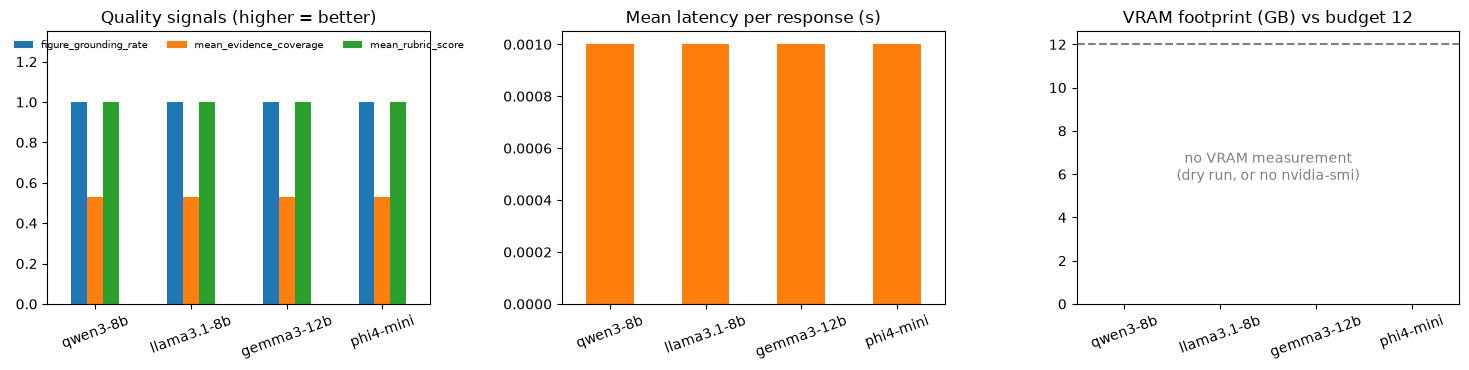

In [13]:
import matplotlib.pyplot as plt


def plot_summary(rows):
    df = pd.DataFrame(rows).set_index("model_name")
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    q = df[["figure_grounding_rate", "mean_evidence_coverage", "mean_rubric_score"]].apply(pd.to_numeric, errors="coerce")
    q.plot.bar(ax=axes[0], ylim=(0, 1.35), rot=20)
    axes[0].legend(loc="upper center", ncol=3, fontsize=7, frameon=False)
    axes[0].set_title("Quality signals (higher = better)")
    pd.to_numeric(df["mean_latency_s"], errors="coerce").plot.bar(ax=axes[1], color="tab:orange", rot=20)
    axes[1].set_title("Mean latency per response (s)")
    vram = pd.to_numeric(df["vram_gb"], errors="coerce")
    vram.plot.bar(ax=axes[2], color="tab:green", rot=20)
    axes[2].axhline(MAX_LLM_VRAM_GB, ls="--", c="gray")
    axes[2].set_title(f"VRAM footprint (GB) vs budget {MAX_LLM_VRAM_GB:g}")
    if vram.isna().all():
        axes[2].text(0.5, 0.5, "no VRAM measurement\n(dry run, or no nvidia-smi)", transform=axes[2].transAxes,
                     ha="center", va="center", color="gray")
    for a in axes:
        a.set_xlabel("")
    plt.tight_layout()
    plt.show()


plot_summary(SUMMARY_ROWS)

### 7b. Read the failures

In [14]:
def show_failures(records, max_items=10):
    """Every gate failure, with the offending IDs -- worth reading before trusting any winner."""
    bad = [r for r in records if r["error"] or r["faithfulness"]["n_hallucinated"]]
    print(f"{len(bad)} problematic response(s) out of {len(records)}")
    for r in bad[:max_items]:
        print("-" * 78)
        print(f"{r['model_name']} | {r['transaction_id']}")
        if r["error"]:
            print("  ERROR:", r["error"])
        else:
            f = r["faithfulness"]
            print("  hallucinated:", f["hallucinated_txn"] + f["hallucinated_accounts"])
            print("  response    :", (r["response_text"] or "")[:400])


show_failures(records)

0 problematic response(s) out of 12


### 7c. Read a few responses

In [15]:
def show_responses(records, n=2):
    """Read a couple of responses side by side -- a five-minute sanity check before the formal human pass."""
    first = [ev["transaction_id"] for ev in EVAL_SAMPLE[:n]]
    for t in first:
        print("=" * 78)
        print(t)
        for r in records:
            if r["transaction_id"] == t:
                body = r["response_text"] if r["error"] is None else f"[ERROR] {r['error']}"
                print(f"\n  [{r['model_name']}]  {body}")


show_responses(records)

TXN00081234

  [qwen3-8b]  [OFFLINE STUB - qwen3-8b] TXN00081234 was flagged as laundering with probability 0.9991 against a threshold of 0.9967. The model weighted log amount paid and is self loop most heavily. The most influential related transaction is TXN00081201.

  [llama3.1-8b]  [OFFLINE STUB - llama3.1-8b] TXN00081234 was flagged as laundering with probability 0.9991 against a threshold of 0.9967. The model weighted log amount paid and is self loop most heavily. The most influential related transaction is TXN00081201.

  [gemma3-12b]  [OFFLINE STUB - gemma3-12b] TXN00081234 was flagged as laundering with probability 0.9991 against a threshold of 0.9967. The model weighted log amount paid and is self loop most heavily. The most influential related transaction is TXN00081201.

  [phi4-mini]  [OFFLINE STUB - phi4-mini] TXN00081234 was flagged as laundering with probability 0.9991 against a threshold of 0.9967. The model weighted log amount paid and is self loop most heavily. The m

## 8. Optional: blind human rating

The automatic metrics check that a response *stays inside and reflects* the evidence. They can't tell which of two
faithful explanations an analyst would rather read — and a small model can pass every check with stilted prose.
A short blind human pass closes that gap, and it is also the strongest thing to cite in the report.

1. `export_for_human_rating(...)` writes `human_rating_sheet.csv` — for ~10 transactions, each model's response under a
   shuffled anonymous label (A/B/C/...), with the evidence next to it — and `human_rating_key.json` (label → model).
   **Raters must not open the key.**
2. Each rater fills `rating_1to5`: *how clear and useful is this for an AML analyst, and does every claim follow from
   the evidence?* (An unsupported claim should cost a point or two.) Split the rows between teammates.
3. `import_human_ratings()` merges the sheet with the key. Section 9 uses the ratings automatically when they exist
   for every surviving model.

Exports are refused for dry runs and never overwrite a sheet that already has ratings.

In [16]:
_sfx = "" if RUN_KIND == "real" else "_DRYRUN"
HUMAN_SHEET = OUT_DIR / f"human_rating_sheet{_sfx}.csv"
HUMAN_KEY = OUT_DIR / f"human_rating_key{_sfx}.json"


def export_for_human_rating(records, sample_by_id, n_transactions=10, seed=RANDOM_SEED, force=False):
    if RUN_KIND != "real" and not force:
        print("RUN_KIND is 'dry' -- not exporting a rating sheet from stub output (force=True only to test the plumbing).")
        return
    if HUMAN_SHEET.exists():
        filled = pd.to_numeric(pd.read_csv(HUMAN_SHEET)["rating_1to5"], errors="coerce").notna().sum()
        if filled:
            raise RuntimeError(f"{HUMAN_SHEET.name} already has {filled} rating(s); refusing to overwrite it.")
    ok = [r for r in records if r["error"] is None]
    models = sorted({r["model_name"] for r in ok})
    assert 2 <= len(models) <= 8, "blind labels support 2-8 models"
    by_txn = {}
    for r in ok:
        by_txn.setdefault(r["transaction_id"], {})[r["model_name"]] = r
    complete = sorted(t for t, d in by_txn.items() if len(d) == len(models))
    rng = random.Random(seed)
    rng.shuffle(complete)
    rows, key = [], {}
    for i, t in enumerate(complete[:n_transactions], 1):
        order = models[:]
        rng.shuffle(order)
        for label, mname in zip("ABCDEFGH", order):
            item = f"{i}-{label}"
            rows.append({"item_id": item, "transaction_id": t, "response_text": by_txn[t][mname]["response_text"],
                         "evidence_json": json.dumps(sample_by_id[t], ensure_ascii=False, separators=(",", ":")),
                         "rating_1to5": ""})
            key[item] = mname
    pd.DataFrame(rows).to_csv(HUMAN_SHEET, index=False)
    HUMAN_KEY.write_text(json.dumps(key, indent=1))
    print(f"Wrote {len(rows)} blind items to {HUMAN_SHEET.name}. Keep {HUMAN_KEY.name} away from the raters.")


def import_human_ratings():
    if not (HUMAN_SHEET.exists() and HUMAN_KEY.exists()):
        return {}
    df = pd.read_csv(HUMAN_SHEET)
    df["rating_1to5"] = pd.to_numeric(df["rating_1to5"], errors="coerce")
    df = df.dropna(subset=["rating_1to5"])
    if df.empty:
        return {}
    df["model_name"] = df["item_id"].map(json.loads(HUMAN_KEY.read_text()))
    return df.groupby("model_name")["rating_1to5"].mean().round(3).to_dict()


# Step 1 (run once after a real run):   export_for_human_rating(records, SAMPLE_BY_ID)
# Step 3 (after the sheet is filled):
HUMAN_RATINGS = import_human_ratings()
print(HUMAN_RATINGS if HUMAN_RATINGS else "No human ratings yet -- Section 9 skips that stage.")

No human ratings yet -- Section 9 skips that stage.


## 9. Select the winner

Same shape as how PNA was chosen: a gate, then ranked stages among the survivors (Decisions 7 and 8).

**Gate** — excluded outright: any failed generation, any hallucinated transaction ID or account, VRAM above
`MAX_LLM_VRAM_GB`.

**Stages** — at each one, every survivor within `TIE_MARGIN` of the best stays in and the next stage decides;
so a 1–2 point difference on a 30-transaction sample is not allowed to pick a winner by itself:

1. figure grounding ↑  →  2. typology claims ↓  →  3. evidence coverage ↑  →  4. human rating ↑ (only if every
survivor has one; margin 0.25)  →  5. rubric ↑  →  finally the cheapest to serve: lower latency, then lower VRAM.

The full audit trail is printed and saved, so the report can say *why* a model won, not just that it did.

In [17]:
STAGES = [("figure_grounding_rate", True), ("typology_claim_rate", False), ("mean_evidence_coverage", True)]


def _val(r, key):
    v = r.get(key)
    if v is None:
        return 1.0 if key == "figure_grounding_rate" else 0.0      # no figures cited = nothing ungrounded
    return v


def select_winner(rows, tie_margin=None, max_vram_gb=None):
    tie_margin = TIE_MARGIN if tie_margin is None else tie_margin
    max_vram_gb = MAX_LLM_VRAM_GB if max_vram_gb is None else max_vram_gb
    audit, survivors = [], []
    for r in rows:
        why = []
        if r["n_runs"] == 0 or r["n_failed"] > 0:
            why.append(f"{r['n_failed']} failed generation(s)")
        if r["hallucinated_ids"] > 0:
            why.append(f"{r['hallucinated_ids']} hallucinated identifier(s)")
        if r["vram_gb"] is not None and r["vram_gb"] > max_vram_gb:
            why.append(f"VRAM {r['vram_gb']} GB > budget {max_vram_gb} GB")
        if why:
            audit.append({"stage": "gate", "model": r["model_name"], "excluded": True, "why": "; ".join(why)})
        else:
            survivors.append(r)
    audit.append({"stage": "gate", "survivors": [r["model_name"] for r in survivors]})

    stages = list(STAGES)
    if survivors and all(r["mean_human_rating"] is not None for r in survivors):
        stages.append(("mean_human_rating", True))
    stages.append(("mean_rubric_score", True))

    for key, higher in stages:
        if len(survivors) <= 1:
            break
        margin = 0.25 if key == "mean_human_rating" else tie_margin
        vals = {r["model_name"]: _val(r, key) for r in survivors}
        best = max(vals.values()) if higher else min(vals.values())
        keep = [r for r in survivors if (vals[r["model_name"]] >= best - margin if higher
                                         else vals[r["model_name"]] <= best + margin)]
        audit.append({"stage": key, "better": "higher" if higher else "lower", "margin": margin, "values": vals,
                      "survivors": [r["model_name"] for r in keep]})
        survivors = keep

    survivors.sort(key=lambda r: (r["mean_latency_s"] if r["mean_latency_s"] is not None else float("inf"),
                                  r["vram_gb"] if r["vram_gb"] is not None else float("inf"), r["model_name"]))
    winner = survivors[0] if survivors else None
    if len(survivors) > 1:
        audit.append({"stage": "efficiency (latency, then VRAM)", "survivors": [r["model_name"] for r in survivors]})
    return winner, audit


def print_audit(audit):
    for a in audit:
        if a.get("excluded"):
            print(f"  GATE  x {a['model']:<14} {a['why']}")
        elif a["stage"] == "gate":
            print(f"  GATE  -> survivors: {a['survivors']}")
        elif "values" in a:
            vals = ", ".join(f"{k}={v:.3f}" for k, v in a["values"].items())
            print(f"  {a['stage']:<24} ({a['better']} is better, margin {a['margin']}): {vals}\n"
                  f"  {'':<24} -> stays in: {a['survivors']}")
        else:
            print(f"  {a['stage']}: {a['survivors']}")


def _row(name, **kw):
    base = dict(model_name=name, params_b=8, n_runs=10, n_failed=0, hallucinated_ids=0, identifiers_cited=20,
                figure_grounding_rate=1.0, typology_claim_rate=0.0, mean_evidence_coverage=0.8, mean_rubric_score=0.95,
                mean_human_rating=None, mean_latency_s=3.0, mean_tokens_per_s=30.0, vram_gb=6.0)
    base.update(kw)
    return base


def test_selection():
    A = _row("A", hallucinated_ids=1, mean_evidence_coverage=0.99, mean_latency_s=0.5)       # gate: hallucinated
    B = _row("B", figure_grounding_rate=0.98, mean_evidence_coverage=0.60)
    C = _row("C", figure_grounding_rate=0.97, mean_evidence_coverage=0.80, mean_latency_s=4.0)
    D = _row("D", figure_grounding_rate=0.80)                                                 # far worse on grounding
    E = _row("E", n_failed=2)                                                                 # gate: failed generations
    F = _row("F", vram_gb=14.0)                                                               # gate: VRAM
    w, audit = select_winner([A, B, C, D, E, F])
    assert w["model_name"] == "C", (w["model_name"], audit)     # B loses on coverage; A/E/F gated; D loses on grounding
    assert [a["model"] for a in audit if a.get("excluded")] == ["A", "E", "F"]
    # a difference inside TIE_MARGIN must not decide: both tie everywhere -> the faster one wins
    w, _ = select_winner([_row("slow", mean_evidence_coverage=0.80, mean_latency_s=6.0),
                          _row("fast", mean_evidence_coverage=0.78, mean_latency_s=2.0)])
    assert w["model_name"] == "fast"
    # human ratings, when present for every survivor, are used
    w, _ = select_winner([_row("x", mean_human_rating=2.0, mean_latency_s=1.0), _row("y", mean_human_rating=4.5, mean_latency_s=9.0)])
    assert w["model_name"] == "y"
    # everyone gated out -> no winner
    w, _ = select_winner([A, E])
    assert w is None
    print("Selection self-tests passed.")


test_selection()

Selection self-tests passed.


In [18]:
SUMMARY_ROWS = aggregate(records, human=HUMAN_RATINGS)
display(pd.DataFrame(SUMMARY_ROWS).sort_values("model_name").reset_index(drop=True))

winner, AUDIT = select_winner(SUMMARY_ROWS)
print("\nSelection audit:")
print_audit(AUDIT)
if RUN_KIND == "dry":
    print("\n*** DRY RUN -- the 'winner' below is meaningless (identical stub output, so latency decided). ***")
print(f"\nWinner: {winner['model_name'] if winner else 'NONE -- every candidate failed the gate'}")
SELECTED_MODEL = next((m for m in CANDIDATE_MODELS if winner and m["name"] == winner["model_name"]), None)

,model_name,params_b,n_runs,n_failed,hallucinated_ids,identifiers_cited,figure_grounding_rate,typology_claim_rate,mean_evidence_coverage,mean_rubric_score,mean_human_rating,mean_latency_s,mean_tokens_per_s,vram_gb
0,gemma3-12b,12.0,3,0,0,5,1.0,0.0,0.5278,1.0,None,0.001,41083.8,None
1,llama3.1-8b,8.0,3,0,0,5,1.0,0.0,0.5278,1.0,None,0.001,41086.3,None
2,phi4-mini,3.8,3,0,0,5,1.0,0.0,0.5278,1.0,None,0.001,41106.0,None
3,qwen3-8b,8.0,3,0,0,5,1.0,0.0,0.5278,1.0,None,0.001,40949.7,None



Selection audit:
  GATE  -> survivors: ['qwen3-8b', 'llama3.1-8b', 'gemma3-12b', 'phi4-mini']
  figure_grounding_rate    (higher is better, margin 0.05): qwen3-8b=1.000, llama3.1-8b=1.000, gemma3-12b=1.000, phi4-mini=1.000
                           -> stays in: ['qwen3-8b', 'llama3.1-8b', 'gemma3-12b', 'phi4-mini']
  typology_claim_rate      (lower is better, margin 0.05): qwen3-8b=0.000, llama3.1-8b=0.000, gemma3-12b=0.000, phi4-mini=0.000
                           -> stays in: ['qwen3-8b', 'llama3.1-8b', 'gemma3-12b', 'phi4-mini']
  mean_evidence_coverage   (higher is better, margin 0.05): qwen3-8b=0.528, llama3.1-8b=0.528, gemma3-12b=0.528, phi4-mini=0.528
                           -> stays in: ['qwen3-8b', 'llama3.1-8b', 'gemma3-12b', 'phi4-mini']
  mean_rubric_score        (higher is better, margin 0.05): qwen3-8b=1.000, llama3.1-8b=1.000, gemma3-12b=1.000, phi4-mini=1.000
                           -> stays in: ['qwen3-8b', 'llama3.1-8b', 'gemma3-12b', 'phi4-mini']
  efficien

## 10. The serving wrapper and the saved configuration

`explain_with_llm(evidence)` is the LLM layer as the backend will call it: adapt the evidence, generate with the
selected model, **re-run the same identifier gate on the live response**, and — *(Decision 9, proposed)* — if it
fails, or generation errors out, return a deterministic evidence-only template instead. An analyst can then never be
shown an invented transaction ID; the worst case is a plainer explanation. The response says which path it took
(`source` = `llm` or `template_fallback`) so the frontend and the logs can show it.

`llm_layer_config.json` records the winner, backend, prompt, decoding settings and the whole audit trail. It is
**only written for a real run** — a dry run must never be able to define the production model.

In [19]:
def template_explanation(ev):
    """Deterministic, evidence-only explanation -- the fallback. Every ID and number in it comes straight from ev."""
    t = ev["target"]
    parts = [f"Transaction {ev['transaction_id']} was flagged as {ev['predicted_label']} (model probability "
             f"{ev['predicted_probability']:.4f}, decision threshold {ev['decision_threshold']:.4f})."]
    if ev.get("confidence_warning"):
        parts.append("The probability is close to or below the decision threshold, so treat this flag with caution.")
    feats = sorted(t.get("feature_attribution", []), key=lambda f: -abs(f.get("importance", 0)))[:3]
    if feats:
        parts.append("The features of this transaction that mattered most to the model were: "
                     + "; ".join(f"{str(f['feature']).replace('_', ' ')} = {f['raw_value']}" for f in feats) + ".")
    nb = sorted(ev.get("neighborhood", []), key=lambda n: n.get("rank", 10**9))[:3]
    parts.append("The most influential related transactions were " + ", ".join(n["transaction_id"] for n in nb) + "."
                 if nb else "No related transactions were available in the evidence.")
    return " ".join(parts)


def explain_with_llm(evidence, model_entry=None, generate_fn=None):
    """Evidence in -> explanation out, guaranteed to contain no identifier that isn't in the evidence."""
    ev = adapt_evidence(evidence)
    m = model_entry or SELECTED_MODEL
    gen = generate_fn or generate_explanation
    try:
        out = gen(m, ev)
    except Exception as e:
        return {"explanation": template_explanation(ev), "source": "template_fallback", "model": m["name"],
                "reason": f"generation failed: {type(e).__name__}"}
    f = faithfulness(ev, out["text"])
    if f["n_hallucinated"] or not out["text"].strip():
        return {"explanation": template_explanation(ev), "source": "template_fallback", "model": m["name"],
                "reason": "identifier check failed: " + ", ".join(f["hallucinated_txn"] + f["hallucinated_accounts"])}
    return {"explanation": out["text"], "source": "llm", "model": m["name"], "latency_s": out["latency_s"], "faithfulness": f}


def test_serving_wrapper():
    m = ACTIVE_MODELS[0]
    bad = lambda mm, ev: {"text": "TXN99999999 is the culprit.", "latency_s": 0.1, "output_tokens": 5}
    boom = lambda mm, ev: (_ for _ in ()).throw(RuntimeError("backend down"))
    assert explain_with_llm(EVAL_SAMPLE[0], m, bad)["source"] == "template_fallback"
    assert explain_with_llm(EVAL_SAMPLE[0], m, boom)["source"] == "template_fallback"
    assert explain_with_llm(EVAL_SAMPLE[0], m, _offline_fake_generate)["source"] == "llm"
    for ev in EVAL_SAMPLE:                                    # the template itself must pass every check it enforces
        tmpl = template_explanation(adapt_evidence(ev))
        s = score_response(adapt_evidence(ev), tmpl)
        assert s["faithfulness"]["n_hallucinated"] == 0 and s["figures"]["ungrounded"] == [], (tmpl, s)
    print("Serving-wrapper self-tests passed.")


test_serving_wrapper()


def save_config(winner, audit, rows):
    if RUN_KIND != "real":
        print("RUN_KIND is 'dry' -> NOT saving llm_layer_config.json (a stub run must never define the production LLM).")
        return None
    if winner is None:
        print("No candidate survived the gate -> nothing saved. Check show_failures(), the prompt (Section 3), "
              "or try a larger candidate.")
        return None
    cfg = {
        "selected_model": {k: v for k, v in SELECTED_MODEL.items()},
        "serving_backend": SERVING_BACKEND,
        "decoding": {"temperature": 0, "seed": RANDOM_SEED, "max_new_tokens": MAX_NEW_TOKENS, "ollama_num_ctx": OLLAMA_NUM_CTX},
        "system_prompt": SYSTEM_PROMPT,
        "selection_audit": audit,
        "summary": rows,
        "evaluation": {"n_transactions": len(EVAL_SAMPLE), "used_mock_evidence": USING_MOCK_EVIDENCE,
                       "provisional": USING_MOCK_EVIDENCE, "human_ratings_used": bool(HUMAN_RATINGS)},
        "fallback": "template_explanation() -- served when the identifier gate fails or generation errors",
        "notebook_version": NOTEBOOK_VERSION,
        "selected_at": datetime.now(timezone.utc).isoformat(),
    }
    path = OUT_DIR / "llm_layer_config.json"
    path.write_text(json.dumps(cfg, indent=2, default=str))
    print(f"Saved {path}" + ("   (PROVISIONAL: mock evidence)" if USING_MOCK_EVIDENCE else ""))
    return path


save_config(winner, AUDIT, SUMMARY_ROWS)

Serving-wrapper self-tests passed.
RUN_KIND is 'dry' -> NOT saving llm_layer_config.json (a stub run must never define the production LLM).


## Next steps

- **Run it for real.** Set `RUN_KIND = "real"` (Section 6) after the Ollama setup in Section 4, with
  `USING_MOCK_EVIDENCE = False` (Section 2). Read `show_failures()`, then do the blind human pass (Section 8)
  before locking the choice — it's the part most worth citing in the report.
- **Make the pipeline importable.** This notebook needs `explain_transaction()`; the FastAPI backend needs it too.
  Moving it (plus its frozen classifier, `pgexplainer_state.pt` loading and the decoders) into a module such as
  `pgexplainer_utils.py` serves both — and the same goes for `build_prompt`, `faithfulness` and `explain_with_llm`
  from this notebook, which are written to be lifted out as-is.
- **Backend design points this notebook informs.** Only predicted-positive transactions ever need an
  explanation (`predicted_positive_edges.pt`), and greedy decoding makes the output deterministic — so the backend
  can precompute and cache explanations for that whole set rather than calling the model per request. The
  `source` field (`llm` / `template_fallback`) belongs in the API response.
- **Limits worth stating in the report.** The identifier gate proves no invented IDs, not that every qualitative
  claim is supported; figure grounding and coverage are lexical heuristics; a few dozen transactions is a small
  sample; runs are greedy and single-pass; 4-bit quantization can move quality slightly; and VRAM/latency were measured
  on a GPU shared with teammates' jobs, so treat them as ranks, not absolutes.
- **Widening the search.** The three disabled registry entries (newer Ollama generations) are one flag away; a
  larger model that fits the GPU budget, or a fine-tuned one, plugs into the same harness unchanged.